# 10 — Uji Statistik: Diebold–Mariano, Model Confidence Set, Arah

Pertanyaan yang dijawab: **apakah selisih kinerja antar-model cukup kuat secara statistik, atau hanya kebetulan?**

**Metode (dan alasannya)**
1. **Diebold–Mariano (DM) + koreksi Harvey–Leybourne–Newbold (HLN)**, satu-sisi (H1: model lebih baik dari pembanding).
   - Forecast h-langkah dengan origin harian saling tumpang-tindih → selisih loss berautokorelasi sampai lag *h−1*. Varians jangka panjang memakai **kernel persegi sampai lag h−1** (bentuk asli DM) + koreksi HLN dan distribusi *t*. (Versi lama memakai kernel Bartlett + normal, yang terlalu mudah menolak H0.)
   - **Loss utama di ruang return** (bebas skala; sama dengan target latih). Loss di ruang harga (rupiah²) tidak stasioner skala (harga naik ≈3×) sehingga didominasi 2025–2026; ruang harga hanya disajikan sebagai pembanding.
2. **Koreksi uji berganda Benjamini–Hochberg (FDR 5%)**: (i) seluruh uji dalam satu setup (105 uji) — ketat; (ii) per (setup, horizon) (21 uji) — longgar. Keduanya dilaporkan.
3. **Model Confidence Set (Hansen–Lunde–Nason, 2011)**, bootstrap blok: himpunan model yang tidak dapat dibedakan dari yang terbaik pada tingkat 90%. Drift ikut sebagai kandidat.
4. **Pesaran–Timmermann** untuk akurasi arah (sampel tak-tumpang-tindih, stride h).

Konvensi tanda: statistik < 0 ⇒ model A **lebih baik**.

In [1]:
import sys, os, json, time, warnings
sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK)
from src import analysis as A, plots as P, stats as S
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
for _d in (RES, RUNS, FIGS):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    """Simpan figur (PNG + PDF) ke outputs/figures lalu tampilkan."""
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

from matplotlib.colors import TwoSlopeNorm
from src.config import MCS_ALPHA, MCS_B

tab = pd.read_csv(os.path.join(RES, 'tabel_hasil_final.csv'))
assert len(tab) == len(ALL_MODELS) * len(HORIZONS) * len(SETUPS), 'jalankan notebook 09 terlebih dahulu'
models_order = list(tab.groupby('model').MAE.mean().sort_values().index)

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44


## 1. 21 model vs Drift

In [2]:
dm = A.dm_vs_drift_table(RES, p, SETUPS, ALL_MODELS, HORIZONS)
dm.to_csv(os.path.join(RES, 'dm_vs_drift_detail.csv'), index=False)
ring = pd.DataFrame({s: A.summarize_dm(dm[dm.setup == s]) for s in SETUPS}).T
ring.loc['total'] = A.summarize_dm(dm)
display(ring)
print('Ruang harga (pembanding, loss kuadrat rupiah): p<0,05 =', int((dm.p_one_hln_price < 0.05).sum()), 'dari', len(dm))

,n_uji,n_p<0.05,n_p<0.10,n_lebih_baik_dari_drift (rel_mse<1),n_q_bh_setup<0.05,n_q_bh_setup_h<0.05
univariat,105,11,23,62,0,1
multivariat,105,5,15,53,0,0
total,210,16,38,115,0,1


Ruang harga (pembanding, loss kuadrat rupiah): p<0,05 = 7 dari 210


Kasus dengan p < 0,05 (satu-sisi, HLN). rel_mse_ret < 1 = lebih baik dari Drift:


,setup,model,horizon,rel_mse_ret,p_one_hln,q_bh_setup,q_bh_setup_h
70,univariat,transformer,1,0.9950,0.0020,0.2017,0.0410
17,univariat,catboost,10,0.9982,0.0038,0.2017,0.0807
114,multivariat,xgboost,30,0.9970,0.0047,0.2750,0.0810
124,multivariat,catboost,30,0.9963,0.0077,0.2750,0.0810
19,univariat,catboost,30,0.9965,0.0096,0.2748,0.1974
122,multivariat,catboost,10,0.9983,0.0104,0.2750,0.2189
18,univariat,catboost,20,0.9956,0.0105,0.2748,0.2198
123,multivariat,catboost,20,0.9979,0.0105,0.2750,0.2200
9,univariat,xgboost,30,0.9942,0.0207,0.4057,0.1974
71,univariat,transformer,5,0.9748,0.0238,0.4057,0.5000


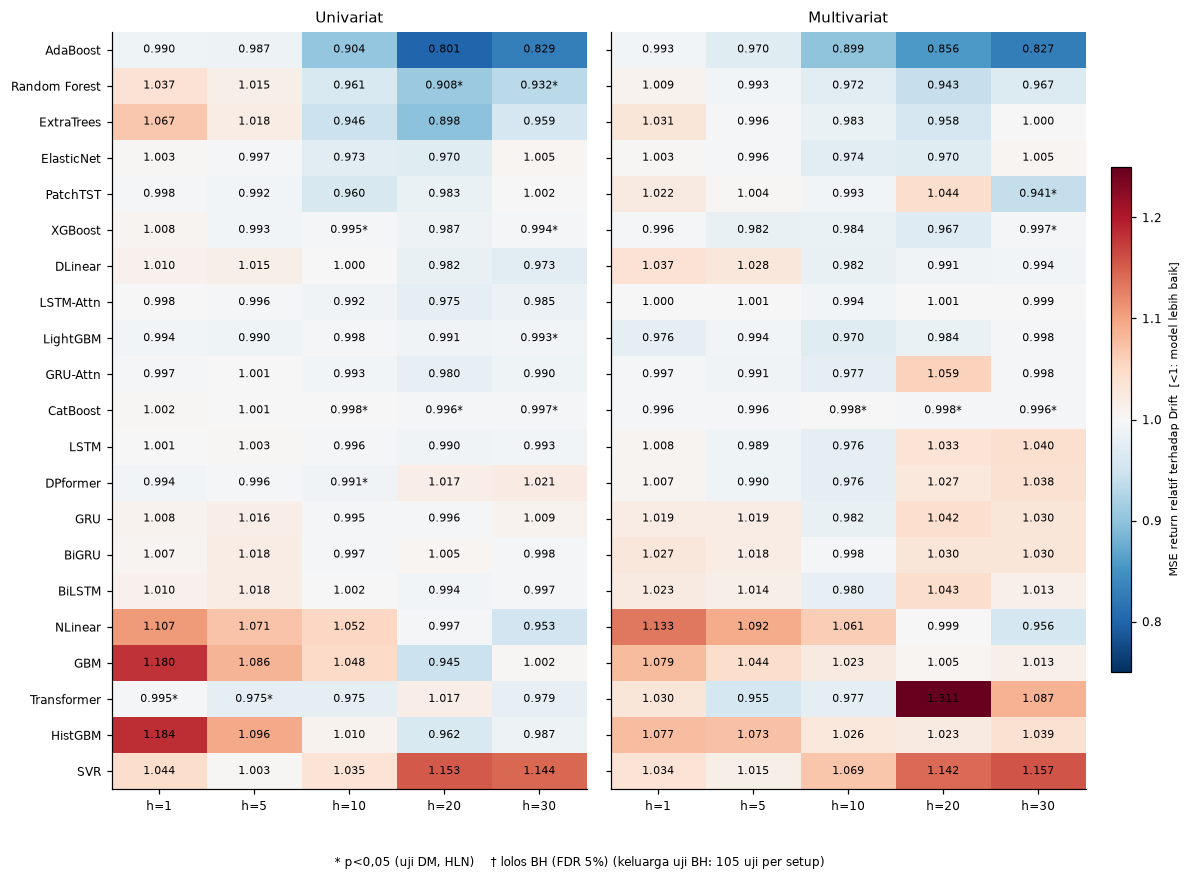

In [3]:
sig = (dm[dm.p_one_hln < 0.05].sort_values('p_one_hln')
       [['setup', 'model', 'horizon', 'rel_mse_ret', 'p_one_hln', 'q_bh_setup', 'q_bh_setup_h']])
print('Kasus dengan p < 0,05 (satu-sisi, HLN). rel_mse_ret < 1 = lebih baik dari Drift:')
display(sig.round(4))
dmp = dm.rename(columns={'rel_mse_ret': 'rel', 'q_bh_setup': 'q_bh'})
fig = P.fig_dm_heatmap(dmp, models_order, HORIZONS)
simpan(fig, 'fig_dm_vs_drift')

## 2. Multivariat vs univariat (apakah 7 indikator makro membantu?)

A = multivariat, B = univariat; `rel_mse_ret < 1` = multivariat lebih baik. Perlu diingat (notebook 03, bagian 6) bahwa fitur makro di eksperimen utama ber-lag-1 dan sebagian informasinya sudah ada di harga — jawaban "tidak membantu" sebagian merupakan konsekuensi desain; skenario B (notebook 15) menguji versi hari-yang-sama.

{'n_uji': 105, 'p<0.05': 5, 'q_bh(seluruh)<0.05': 0, 'q_bh(per horizon)<0.05': 2, 'multivariat lebih baik (rel<1)': 40}


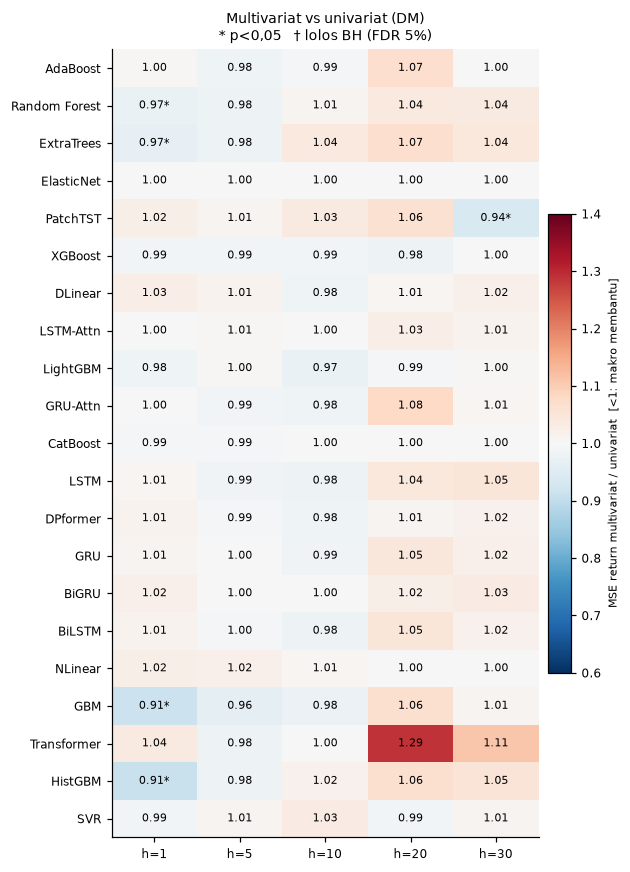

,model,horizon,rel_mse_ret,p_one_hln,q_bh,q_bh_h
35,hist_gbm,1,0.9098,0.0010,0.0689,0.0138
20,gbm,1,0.9146,0.0013,0.0689,0.0138
30,extra_trees,1,0.9663,0.0102,0.3564,0.0713
10,rf,1,0.9733,0.0215,0.5649,0.1130
89,patchtst,30,0.9392,0.0295,0.6199,0.6199


In [4]:
mu = A.dm_multi_vs_uni_table(RES, p, ALL_MODELS, HORIZONS)
mu.to_csv(os.path.join(RES, 'dm_multivariat_vs_univariat_detail.csv'), index=False)
print({'n_uji': len(mu), 'p<0.05': int((mu.p_one_hln < 0.05).sum()), 'q_bh(seluruh)<0.05': int((mu.q_bh < 0.05).sum()),
       'q_bh(per horizon)<0.05': int((mu.q_bh_h < 0.05).sum()), 'multivariat lebih baik (rel<1)': int((mu.rel_mse_ret < 1).sum())})
mat = mu.pivot(index='model', columns='horizon', values='rel_mse_ret').reindex(index=models_order, columns=HORIZONS)
pm = mu.pivot(index='model', columns='horizon', values='p_one_hln').reindex(index=models_order, columns=HORIZONS)
qm = mu.pivot(index='model', columns='horizon', values='q_bh').reindex(index=models_order, columns=HORIZONS)
fig, ax = plt.subplots(figsize=(5.8, 0.3 * len(models_order) + 1.7))
im = ax.imshow(mat.values, cmap='RdBu_r', norm=TwoSlopeNorm(1.0, 0.6, 1.4), aspect='auto')
ax.set_xticks(range(len(HORIZONS))); ax.set_xticklabels([f'h={h}' for h in HORIZONS])
ax.set_yticks(range(len(models_order))); ax.set_yticklabels([P.label(m) for m in models_order])
for i in range(len(models_order)):
    for j in range(len(HORIZONS)):
        v = mat.values[i, j]
        if np.isfinite(v):
            mk = '†' if qm.values[i, j] < 0.05 else ('*' if pm.values[i, j] < 0.05 else '')
            ax.text(j, i, f'{v:.2f}{mk}', ha='center', va='center', fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02).set_label('MSE return multivariat / univariat  [<1: makro membantu]', fontsize=7.5)
ax.set_title('Multivariat vs univariat (DM)\n* p<0,05   † lolos BH (FDR 5%)', fontsize=9)
fig.tight_layout()
simpan(fig, 'fig_dm_multi_vs_uni')
display(mu[mu.p_one_hln < 0.05].sort_values('p_one_hln')[['model', 'horizon', 'rel_mse_ret', 'p_one_hln', 'q_bh', 'q_bh_h']].round(4))

## 3. Model Confidence Set (90%)

Himpunan yang tak dapat dibedakan dari model terbaik pada tingkat 90% (loss kuadrat return, bootstrap blok, Tmax). **MCS yang besar = data tidak cukup informatif untuk memisahkan model** — itu sendiri temuan penting. Bila Drift ikut berada di dalam MCS, tidak ada bukti bahwa model-model yang lebih rumit lebih baik.

Jumlah anggota MCS (dari 22 kandidat = 21 model + Drift), tingkat 90%:


,Univ. h=1,Univ. h=5,Univ. h=10,Univ. h=20,Univ. h=30,Multi. h=1,Multi. h=5,Multi. h=10,Multi. h=20,Multi. h=30
anggota,17,22,22,21,22,22,22,21,19,21


Drift di dalam MCS?


,Univ. h=1,Univ. h=5,Univ. h=10,Univ. h=20,Univ. h=30,Multi. h=1,Multi. h=5,Multi. h=10,Multi. h=20,Multi. h=30
drift,True,True,True,True,True,True,True,True,True,True


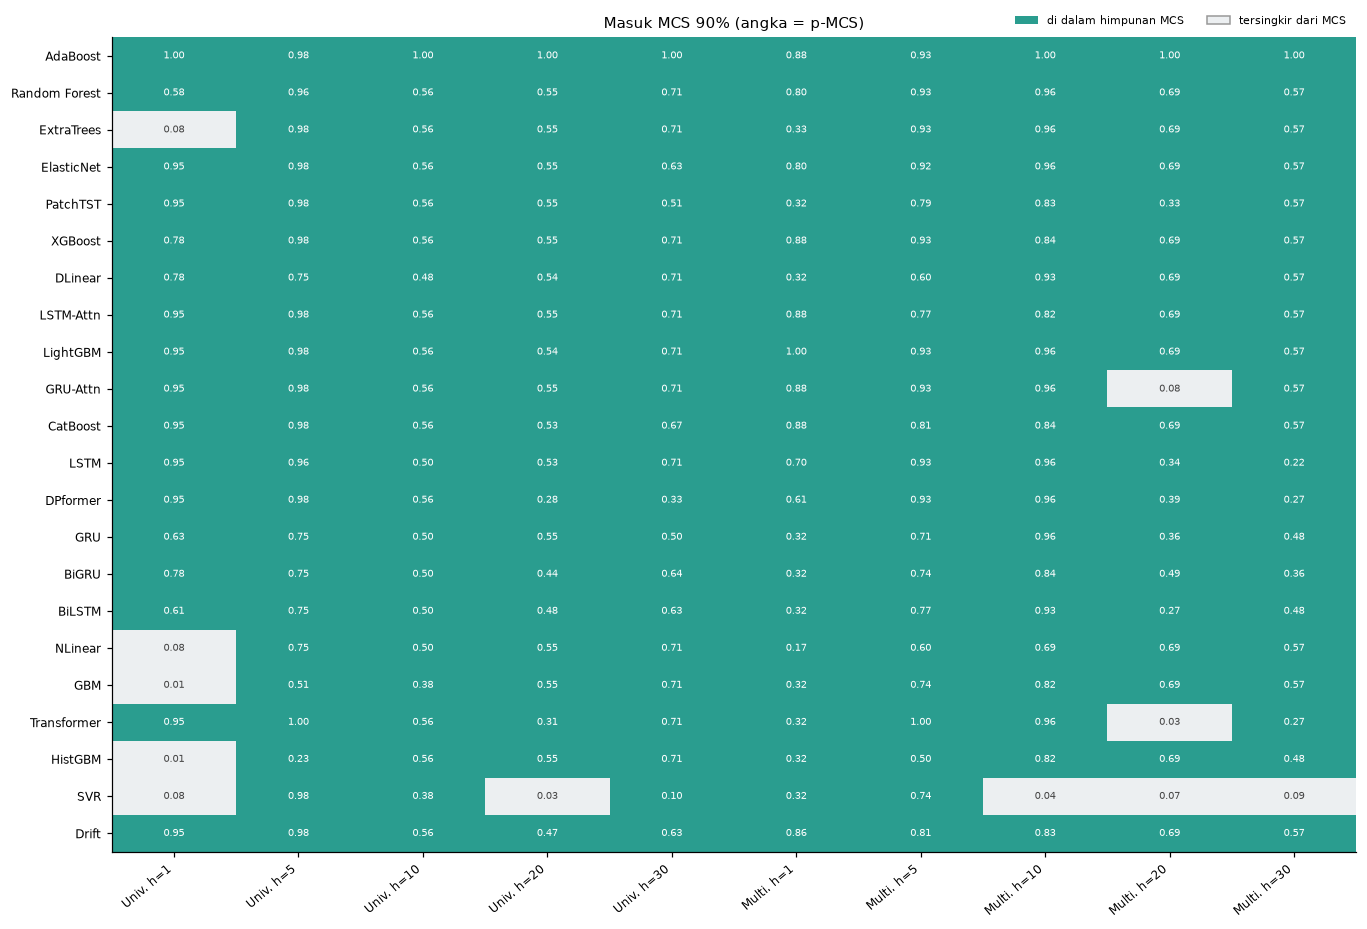

In [5]:
incl, pv = A.mcs_tables(RES, p, SETUPS, ALL_MODELS, HORIZONS, alpha=MCS_ALPHA, B=MCS_B, seed=0)
incl.to_csv(os.path.join(RES, 'mcs_keanggotaan.csv'))
pv.to_csv(os.path.join(RES, 'mcs_pvalue.csv'))
n_cand = len(ALL_MODELS) + 1
print(f'Jumlah anggota MCS (dari {n_cand} kandidat = 21 model + Drift), tingkat {100 * (1 - MCS_ALPHA):.0f}%:')
display(incl.sum().astype(int).to_frame('anggota').T)
print('Drift di dalam MCS?'); display(incl.loc[['drift']])
fig = P.fig_mcs(incl, pv, models=models_order + ['drift'])
simpan(fig, 'fig_mcs')

## 4. Akurasi arah (Pesaran–Timmermann)

Uji apakah **tanda** return prediksi berasosiasi dengan tanda aktual. Hasil tak terdefinisi (NaN) bila prediksi selalu satu tanda (mis. selalu naik), yang umum untuk model yang hampir konstan. Mengingat 52–69% hari uji adalah kenaikan, akurasi arah yang tinggi dapat berasal dari bias naik, bukan keahlian — karena itu PT dibandingkan dengan akurasi yang diharapkan secara kebetulan (`p_star`).

In [6]:
mt = pd.read_csv(os.path.join(RES, 'metrik_return.csv'))
ok = mt.p_one_pt.notna()
q_pt = np.full(len(mt), np.nan)
q_pt[ok.values] = S.bh_fdr(mt.loc[ok, 'p_one_pt'].values, 0.05)[0]
mt['q_bh_pt'] = q_pt
print(f"Uji PT terdefinisi pada {int(ok.sum())} dari {len(mt)} kombinasi; p<0,05: {int((mt.p_one_pt < 0.05).sum())}; lolos BH: {int((mt.q_bh_pt < 0.05).sum())}")
mt.to_csv(os.path.join(RES, 'metrik_return_arah.csv'), index=False)
display(mt[mt.p_one_pt < 0.05].sort_values('p_one_pt')[['setup', 'model', 'horizon', 'hit_pt', 'base_up', 'pred_up', 'p_one_pt', 'q_bh_pt']].round(4))
print('Median akurasi arah (seluruh hari uji) per horizon vs porsi hari naik:')
display(mt.groupby('horizon').agg(hit_median=('hit_all', 'median'), porsi_naik=('base_up', 'median')).round(3))

Uji PT terdefinisi pada 167 dari 210 kombinasi; p<0,05: 29; lolos BH: 0


,setup,model,horizon,hit_pt,base_up,pred_up,p_one_pt,q_bh_pt
156,multivariat,lstm,5,0.6243,0.5491,0.7514,0.0011,0.1072
141,multivariat,hist_gbm,5,0.6185,0.5491,0.6416,0.0019,0.1072
85,univariat,patchtst,1,0.5509,0.5231,0.5440,0.0019,0.1072
182,multivariat,dlinear,10,0.6782,0.6092,0.7471,0.0030,0.1130
167,multivariat,bilstm,10,0.6782,0.6092,0.8161,0.0034,0.1130
105,multivariat,lightgbm,1,0.5498,0.5231,0.7697,0.0046,0.1222
161,multivariat,gru,5,0.6069,0.5491,0.6763,0.0056,0.1222
116,multivariat,rf,5,0.6069,0.5491,0.7110,0.0059,0.1222
171,multivariat,bigru,5,0.6012,0.5491,0.6590,0.0084,0.1516
21,univariat,gbm,5,0.6012,0.5491,0.7168,0.0094,0.1516


Median akurasi arah (seluruh hari uji) per horizon vs porsi hari naik:


,hit_median,porsi_naik
horizon,,
1,0.511,0.523
5,0.574,0.549
10,0.610,0.609
20,0.656,0.636
30,0.683,0.759


## 5. Ringkasan otomatis (angka dihitung dari tabel di atas)

In [7]:
n = len(dm)
txt = f"""
- Dari {n} perbandingan (21 model × 5 horizon × 2 setup), {int((dm.rel_mse_ret < 1).sum())} memiliki MSE-return lebih kecil dari Drift,
  tetapi hanya {int((dm.p_one_hln < 0.05).sum())} yang signifikan pada p<0,05 (satu-sisi, HLN).
  Setelah koreksi BH (FDR 5%): {int((dm.q_bh_setup < 0.05).sum())} lolos (keluarga = seluruh uji dalam satu setup) dan
  {int((dm.q_bh_setup_h < 0.05).sum())} lolos (keluarga = per setup×horizon).
- Multivariat vs univariat: {int((mu.p_one_hln < 0.05).sum())} dari {len(mu)} signifikan pada p<0,05; {int((mu.q_bh < 0.05).sum())} lolos BH.
- MCS 90% memuat {int(incl.sum().min())}–{int(incl.sum().max())} dari {len(ALL_MODELS) + 1} kandidat; Drift berada di dalam MCS pada {int(incl.loc['drift'].sum())} dari {incl.shape[1]} kondisi.
"""
print(txt)


- Dari 210 perbandingan (21 model × 5 horizon × 2 setup), 115 memiliki MSE-return lebih kecil dari Drift,
  tetapi hanya 16 yang signifikan pada p<0,05 (satu-sisi, HLN).
  Setelah koreksi BH (FDR 5%): 0 lolos (keluarga = seluruh uji dalam satu setup) dan
  1 lolos (keluarga = per setup×horizon).
- Multivariat vs univariat: 5 dari 105 signifikan pada p<0,05; 0 lolos BH.
- MCS 90% memuat 17–22 dari 22 kandidat; Drift berada di dalam MCS pada 10 dari 10 kondisi.



### Kesimpulan yang boleh (dan tidak boleh) ditulis

- Jika hampir tidak ada model yang lolos koreksi uji berganda dan Drift berada di dalam MCS, kesimpulan yang **jujur** adalah: *tidak ada bukti statistik yang kuat bahwa satu model mengalahkan Drift secara konsisten pada return emas Antam*; perbedaan MAE antar-model sebagian besar berada dalam rentang ketidakpastian sampling. Ini konsisten dengan hipotesis pasar yang hampir efisien dan **bukan** kegagalan penelitian — banyak makalah q1 melaporkan hasil nol serupa, dengan tambahan analisis ketahanan (notebook 12, 13, 16).
- Jangan menulis "model X terbaik secara signifikan" bila X tidak lolos DM terhadap Drift. Gunakan kalimat deskriptif ("MAE terendah pada kondisi ...") dan sebutkan hasil uji.
- Hasil p<0,05 yang tidak lolos BH bersifat eksploratori (dari 210 uji, ≈10 hasil p<0,05 diharapkan muncul **hanya karena kebetulan**).